# Transformer. Seminar 3. Токенизация

На прошлых семинарах на вход уже лежали номера токенов. Сегодня разбираем, откуда берутся эти номера.

Сначала словами: чем BPE, WordPiece и Unigram отличаются и кто ими пользуется. Потом берём новости Gazeta и пишем BPE сами. Частоты не задаём руками: считаем по тексту. В конце, если останется время, смотрим, как устроен вход BERT.

## 0. Зависимости

In [1]:
import gzip
import hashlib
import os
import time
from pathlib import Path

os.environ.setdefault("MPLCONFIGDIR", str(Path(".mplconfig").resolve()))
os.environ.setdefault("HF_HOME", str(Path(".hf_cache").resolve()))

import matplotlib.pyplot as plt
from tqdm.auto import tqdm

plt.rcParams["figure.dpi"] = 120
plt.rcParams["font.family"] = "DejaVu Sans"


def show_tokens(rows, title=None):
    # rows: список (подпись, список кусков)
    fig, ax = plt.subplots(figsize=(9, 0.46 * len(rows) + 0.55))
    ax.set_xlim(0, 1)
    ax.set_ylim(-0.55, len(rows) - 0.45)
    ax.axis("off")
    for i, (label, toks) in enumerate(rows):
        y = len(rows) - 1 - i
        ax.text(0.0, y, label, ha="left", va="center", fontsize=11, color="#333")
        weights = [max(len(tok), 1) for tok in toks]
        x = 0.24
        usable = 0.74
        gap = 0.008 * (len(toks) > 1)
        scale = (usable - gap * (len(toks) - 1)) / sum(weights)
        for tok, w in zip(toks, weights):
            width = max(scale * w, 0.045)
            if tok == "[UNK]":
                color = "#d9d9d9"
            else:
                color = plt.cm.Set2(int(hashlib.md5(tok.encode()).hexdigest(), 16) % 8)
            ax.add_patch(plt.Rectangle((x, y - 0.32), width, 0.64, facecolor=color, edgecolor="#333", lw=0.6))
            ax.text(x + width / 2, y, tok, ha="center", va="center", fontsize=11)
            x += width + gap
    if title:
        ax.set_title(title, loc="left", fontsize=12)
    plt.tight_layout()
    plt.show()


def show_bars(pairs, title, xlabel):
    # pairs: список (подпись или пара кусков, число). Первое — выбранное.
    labels = []
    for key, _ in pairs:
        if isinstance(key, str):
            labels.append(key)
        else:
            labels.append(key[0] + " + " + key[1])
    vals = [v for _, v in pairs]
    order = list(reversed(range(len(vals))))
    colors = ["#d95f02" if i == 0 else "#9ecae1" for i in range(len(vals))]
    plt.figure(figsize=(7.2, 0.38 * len(vals) + 1.1))
    plt.barh([labels[i] for i in order], [vals[i] for i in order], color=[colors[i] for i in order])
    plt.xlabel(xlabel)
    plt.title(title)
    plt.tight_layout()
    plt.show()


print("картинки готовы")

картинки готовы


/Users/fedorkurushin/Documents/ChatGPT/seminars_mephi/transformers/.venv/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Три алгоритма

Модели не читают текст. Им нужна последовательность номеров из фиксированного словаря. Словарь собирают заранее, одним из трёх алгоритмов. Дальше по коду пишем только BPE. Здесь — чем они отличаются, чтобы потом было с чем сравнить нарезку.

### BPE

Старт: каждое слово разрезано на буквы. На каждом шаге находят два куска, которые чаще всего стоят рядом, и склеивают их в один новый токен. Так повторяют, пока словарь не станет нужного размера.

Плюс: правило простое, его можно написать за семинар. Токенизатор GPT-2, RoBERTa и Llama — это BPE, часто по байтам, а не по буквам. Байты закрывают любой символ, отдельный `[UNK]` не нужен.

Минус: критерий — частота. В русский словарь попадёт «ст», потому что так часто пишут, а не потому что это приставка. Разрез у слова один, вероятностей нет.

### WordPiece

Тот же цикл «склеивай, пока словарь не заполнится». Другая оценка пары: сколько раз куски встретились вместе, делённое на произведение их частот по отдельности.

$$\mathrm{score}(A, B) = \frac{\mathrm{freq}(AB)}{\mathrm{freq}(A) \cdot \mathrm{freq}(B)}$$

Пара, которая почти не встречается порознь, обгоняет пару, которая просто часто мелькает в тексте. Так устроен словарь BERT. На готовом тексте берут самый длинный кусок словаря от начала слова. Если слово из кусков не собирается, подставляют `[UNK]` на всё слово, не на одну букву. Продолжение слова помечают `##`.

Плюс: в словаре остаются куски, которые держатся вместе. Минус: формулу руками уже не проверишь на глаз, а `[UNK]` съедает слово целиком.

### Unigram

Идут с другой стороны. Начинают с большого словаря и выкидывают токены, без которых текст всё ещё хорошо кодируется. У одного слова несколько разрезов, у каждого есть вероятность, берут самый вероятный.

Плюс: так режут языки, где нет надёжных пробелов. T5, XLNet, ALBERT учат через SentencePiece в режиме Unigram. Минус: обучение — это EM, на семинаре его не пишем.

SentencePiece — не четвёртый алгоритм, а программа вокруг BPE или Unigram. Пробел она прячет в символ `▁` в начале куска, поэтому нарезку можно склеить обратно в исходную строку.

### Когда какой

Генерировать текст и не хотеть `[UNK]` — BPE по байтам. Энкодер вроде BERT — WordPiece. Много языков в одной модели — Unigram через SentencePiece.

## 2. Gazeta

Текст — train датасета Gazeta (Илья Гусев, 2020): 60964 новостей, файл `data/gazeta_train.txt.gz`. В аудитории интернет не нужен.

Наш цикл на всём train слишком медленный: каждый шаг заново обходит все слова. Для ручного BPE берём первые 2000 статей. Библиотека ниже учится на всём файле.

In [2]:
with gzip.open("data/gazeta_train.txt.gz", "rt", encoding="utf-8") as f:
    news = [line.strip() for line in f if line.strip()]

In [3]:
docs = news[:2000]
print(f"статей в файле {len(news)}, берём {len(docs)}")
print(docs[0][:240])

статей в файле 60964, берём 2000
Сегодня транспортный налог начисляется в зависимости от мощности автомобиля, причем цена для «сильных» машин выше, чем для малолитражек. Также ставку налога могут корректировать региональные власти: согласно Налоговому кодексу, базовый тари


слова 3, буквы 24


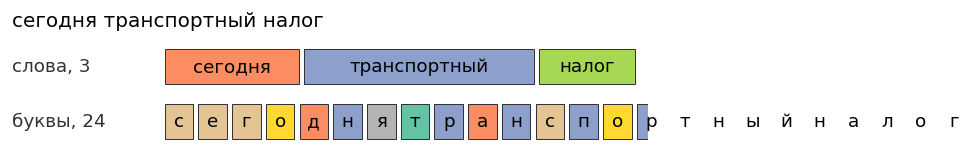

In [4]:
phrase = " ".join(docs[0].split()[:3]).lower()
words = phrase.split()
chars = list("".join(words))
print(f"слова {len(words)}, буквы {len(chars)}")
show_tokens([
    (f"слова, {len(words)}", words),
    (f"буквы, {len(chars)}", chars),
], title=phrase)

Три слова — это три позиции для attention. Те же слова буквами — уже пара десятков позиций, а матрица внимания растёт как длина в квадрате. Словарь из целых слов на новостях тоже плох: редкая форма и опечатка выпадают в `[UNK]`. Субслова сидят между этими двумя крайностями. Их и будем строить.

Сначала текст приводят в порядок. Иначе «автомобиля,» и «автомобиля» — разные строки, и запятая попадает в словарь.

1. нижний регистр, `ё` → `е`;
2. всё, что не буква и не пробел, меняем на пробел;
3. режем по пробелам. BPE границу пробела не переходит;
4. считаем, сколько раз встретилось каждое слово.

### Нормализация

«России» и «россии» станут одним словом. «её» будет из тех же букв, что «ее».

In [5]:
def normalize(text):
    return text.lower().replace("ё", "е")


print(normalize(docs[0][:220]))

сегодня транспортный налог начисляется в зависимости от мощности автомобиля, причем цена для «сильных» машин выше, чем для малолитражек. также ставку налога могут корректировать региональные власти: согласно налоговому к


### Задание. Убери мусор

В `clean` оставь буквы и пробел. Запятую, кавычки, цифры, дефис замени пробелом.

In [6]:
import re

def clean(text):
    text = normalize(text)
    text = re.sub(r"[^а-яА-Я\s]", " ", text)
    return " ".join(text.split())

### Предтокенизация

`split` режет по пробелам и схлопывает те, что появились на месте запятых. Дальше каждое слово живёт отдельно.

In [7]:
def pretokenize(text):
    return text.split()


print(pretokenize(clean(docs[0]))[:12])

['сегодня', 'транспортный', 'налог', 'начисляется', 'в', 'зависимости', 'от', 'мощности', 'автомобиля', 'причем', 'цена', 'для']


### Задание. Посчитай частоты

Пройди по словам всех 2000 статей. Если слова ещё нет в `freqs`, положи 0, потом прибавь 1.

Числа ниже — не пример из лекции. Это сколько раз слово реально стоит в этих статьях.

In [8]:
def word_freqs(docs):
    freqs = {}
    for line in docs:
        for word in pretokenize(clean(line)):
            if word not in freqs:
                freqs[word] = 1
            else:
                freqs[word] += 1
    return freqs

In [9]:
new_word_freqs = word_freqs(news)

In [10]:
new_word_freqs

{'сегодня': 13393,
 'транспортный': 341,
 'налог': 1055,
 'начисляется': 31,
 'в': 1659259,
 'зависимости': 2582,
 'от': 123978,
 'мощности': 941,
 'автомобиля': 3643,
 'причем': 8803,
 'цена': 3971,
 'для': 139356,
 'сильных': 685,
 'машин': 3494,
 'выше': 6378,
 'чем': 32980,
 'малолитражек': 12,
 'также': 101787,
 'ставку': 1714,
 'налога': 1139,
 'могут': 22876,
 'корректировать': 121,
 'региональные': 822,
 'власти': 21790,
 'согласно': 13816,
 'налоговому': 50,
 'кодексу': 241,
 'базовый': 209,
 'тариф': 384,
 'установленный': 357,
 'правительством': 1679,
 'может': 50838,
 'быть': 30550,
 'уменьшен': 24,
 'пять': 10222,
 'раз': 31389,
 'или': 47370,
 'увеличен': 188,
 'до': 101968,
 'сборы': 1428,
 'идут': 2378,
 'бюджеты': 268,
 'откуда': 1603,
 'растекаются': 4,
 'на': 719069,
 'общие': 982,
 'нужды': 494,
 'один': 32615,
 'из': 198627,
 'основных': 2143,
 'источников': 2135,
 'бюджетных': 1273,
 'доходов': 2784,
 'предлагается': 1399,
 'направить': 896,
 'исключительно': 2811

### Решение

In [11]:
len(docs)

2000

разных слов 100870


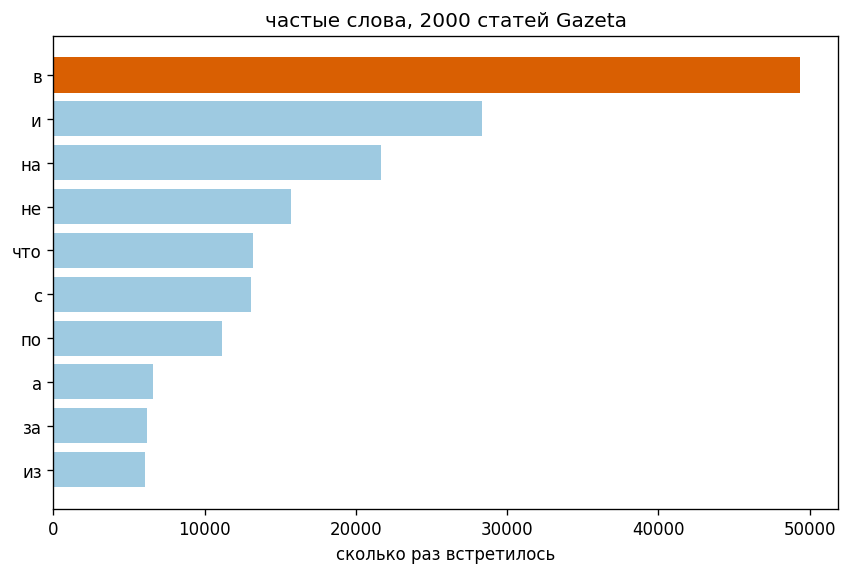

 2104  р о с с и и
   51  н а л о г
   33  и н ф л я ц и я
   14  ц е н т р о б а н к


In [12]:
def word_freqs(docs):
    freqs = {}
    for line in docs:
        for word in pretokenize(clean(line)):
            if word not in freqs:
                freqs[word] = 0
            freqs[word] += 1
    return freqs


freqs_g = word_freqs(docs)
print(f"разных слов {len(freqs_g)}")

top_words = sorted(freqs_g.items(), key=lambda kv: -kv[1])[:10]
show_bars(top_words, "частые слова, 2000 статей Gazeta", "сколько раз встретилось")

for word in ["россии", "налог", "инфляция", "центробанк"]:
    print(f"{freqs_g[word]:5d}  {' '.join(word)}")

In [13]:
corpus_g = {tuple(word): n for word, n in freqs_g.items()}
alphabet_g = set()
for word in corpus_g:
    alphabet_g.update(word)
print(f"букв {len(alphabet_g)}")

букв 32


In [14]:
corpus_g

{('с', 'е', 'г', 'о', 'д', 'н', 'я'): 328,
 ('т', 'р', 'а', 'н', 'с', 'п', 'о', 'р', 'т', 'н', 'ы', 'й'): 27,
 ('н', 'а', 'л', 'о', 'г'): 51,
 ('н', 'а', 'ч', 'и', 'с', 'л', 'я', 'е', 'т', 'с', 'я'): 1,
 ('в',): 49384,
 ('з', 'а', 'в', 'и', 'с', 'и', 'м', 'о', 'с', 'т', 'и'): 70,
 ('о', 'т'): 3596,
 ('м', 'о', 'щ', 'н', 'о', 'с', 'т', 'и'): 24,
 ('а', 'в', 'т', 'о', 'м', 'о', 'б', 'и', 'л', 'я'): 139,
 ('п', 'р', 'и', 'ч', 'е', 'м'): 352,
 ('ц', 'е', 'н', 'а'): 154,
 ('д', 'л', 'я'): 3800,
 ('с', 'и', 'л', 'ь', 'н', 'ы', 'х'): 25,
 ('м', 'а', 'ш', 'и', 'н'): 216,
 ('в', 'ы', 'ш', 'е'): 184,
 ('ч', 'е', 'м'): 1068,
 ('м', 'а', 'л', 'о', 'л', 'и', 'т', 'р', 'а', 'ж', 'е', 'к'): 1,
 ('т', 'а', 'к', 'ж', 'е'): 2271,
 ('с', 'т', 'а', 'в', 'к', 'у'): 46,
 ('н', 'а', 'л', 'о', 'г', 'а'): 56,
 ('м', 'о', 'г', 'у', 'т'): 587,
 ('к', 'о', 'р', 'р', 'е', 'к', 'т', 'и', 'р', 'о', 'в', 'а', 'т', 'ь'): 3,
 ('р', 'е', 'г', 'и', 'о', 'н', 'а', 'л', 'ь', 'н', 'ы', 'е'): 45,
 ('в', 'л', 'а', 'с', 'т', '

## 3. BPE на этих частотах

Корпус для BPE — те же слова, только каждое записано кортежем букв. Число рядом — частота из ячейки выше. «россии» весит столько, сколько раз оно встретилось, а не единицу.

Шаг алгоритма: посчитать, сколько раз каждая пара стоит рядом, склеить самую частую, записать правило. Повторить.

### Задание. Частоты пар

Пара внутри частого слова должна весить как это слово. Если прибавлять 1, «россии» (тысячи раз) и опечатка (один раз) дадут одинаковый вклад.

In [15]:
def pair_counts(corpus):
    counts = {}
    for word, freq in corpus.items():
        for i in range(len(word) - 1):
            pair = (word[i], word[i + 1])
            if pair not in counts:
                counts[pair] = 0
            counts[pair] += freq
    return counts

### Решение

In [16]:
corpus_g

{('с', 'е', 'г', 'о', 'д', 'н', 'я'): 328,
 ('т', 'р', 'а', 'н', 'с', 'п', 'о', 'р', 'т', 'н', 'ы', 'й'): 27,
 ('н', 'а', 'л', 'о', 'г'): 51,
 ('н', 'а', 'ч', 'и', 'с', 'л', 'я', 'е', 'т', 'с', 'я'): 1,
 ('в',): 49384,
 ('з', 'а', 'в', 'и', 'с', 'и', 'м', 'о', 'с', 'т', 'и'): 70,
 ('о', 'т'): 3596,
 ('м', 'о', 'щ', 'н', 'о', 'с', 'т', 'и'): 24,
 ('а', 'в', 'т', 'о', 'м', 'о', 'б', 'и', 'л', 'я'): 139,
 ('п', 'р', 'и', 'ч', 'е', 'м'): 352,
 ('ц', 'е', 'н', 'а'): 154,
 ('д', 'л', 'я'): 3800,
 ('с', 'и', 'л', 'ь', 'н', 'ы', 'х'): 25,
 ('м', 'а', 'ш', 'и', 'н'): 216,
 ('в', 'ы', 'ш', 'е'): 184,
 ('ч', 'е', 'м'): 1068,
 ('м', 'а', 'л', 'о', 'л', 'и', 'т', 'р', 'а', 'ж', 'е', 'к'): 1,
 ('т', 'а', 'к', 'ж', 'е'): 2271,
 ('с', 'т', 'а', 'в', 'к', 'у'): 46,
 ('н', 'а', 'л', 'о', 'г', 'а'): 56,
 ('м', 'о', 'г', 'у', 'т'): 587,
 ('к', 'о', 'р', 'р', 'е', 'к', 'т', 'и', 'р', 'о', 'в', 'а', 'т', 'ь'): 3,
 ('р', 'е', 'г', 'и', 'о', 'н', 'а', 'л', 'ь', 'н', 'ы', 'е'): 45,
 ('в', 'л', 'а', 'с', 'т', '

 96597  с + т
 81628  т + о
 77234  н + и
 77034  н + о
 76183  н + а
 74748  е + н
 74228  о + в
 73133  р + о


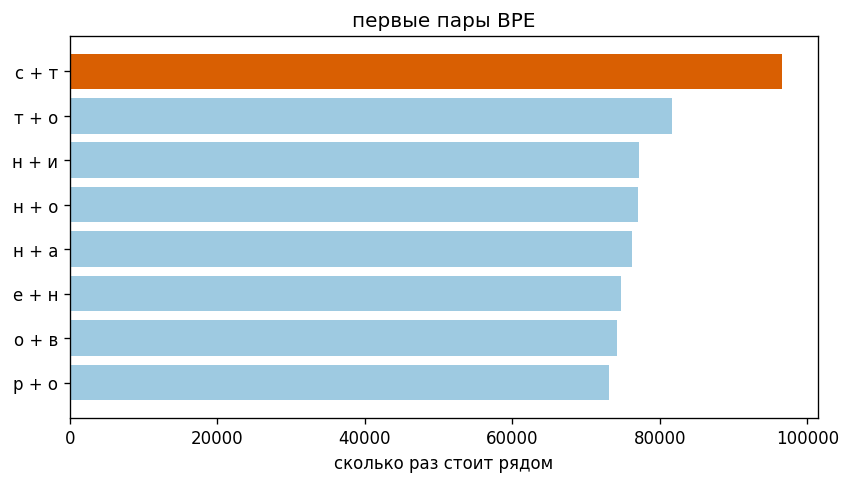

In [17]:
ranked = sorted(pair_counts(corpus_g).items(), key=lambda kv: -kv[1])
for pair, n in ranked[:8]:
    print(f"{n:6d}  {pair[0]} + {pair[1]}")
show_bars(ranked[:8], "первые пары BPE", "сколько раз стоит рядом")

Оранжевый столбец — пара, которую BPE склеит первой. Это «с» + «т». Не приставка и не корень: в этих новостях буквы просто чаще всего стоят рядом, например в слове «мощности» из первой статьи.

Склейка идёт слева направо и не заходит на саму себя. «налог» этой пары не содержит, слово не меняется.

In [18]:
def apply_merge(tokens, pair):
    a, b = pair
    new_tokens = []
    i = 0
    while i < len(tokens):
        if i + 1 < len(tokens) and tokens[i] == a and tokens[i + 1] == b:
            new_tokens.append(a + b)
            i += 2
        else:
            new_tokens.append(tokens[i])
            i += 1
    return new_tokens


def most_frequent_pair(counts):
    best_pair = None
    best_n = -1
    for pair, n in counts.items():
        if n > best_n:
            best_pair = pair
            best_n = n
    return best_pair


best = most_frequent_pair(pair_counts(corpus_g))
print(best, pair_counts(corpus_g)[best])
for word in ["мощности", "налог"]:
    print(f"{word:12} {' '.join(apply_merge(list(word), best))}")

('с', 'т') 96597
мощности     м о щ н о ст и
налог        н а л о г


Дальше то же самое в цикле. Каждое новое правило дописывают в конец списка. Чтобы разрезать слово, которого мы ещё не склеивали целиком, каждый раз берут ту пару из списка, которая стоит в слове сейчас и выучена раньше всех. Буквы, которой не было в корпусе, заменяют на `[UNK]`.

80 слияний на 2000 статьях — это ещё маленький словарь: 65 букв и 80 кусков. Частые слова только начинают собираться.

In [19]:
def merge_corpus(corpus, pair):
    merged = {}
    for word, freq in corpus.items():
        merged[tuple(apply_merge(word, pair))] = freq
    return merged


def encode_word(word, merges, alphabet):
    # номер правила — приоритет: клеим ту пару из списка, которая сейчас стоит в слове и выучена раньше всех
    rank = {pair: i for i, pair in enumerate(merges)}
    tokens = [ch if ch in alphabet else "[UNK]" for ch in word]
    while True:
        best_i = None
        best_rank = None
        for i in range(len(tokens) - 1):
            pair = (tokens[i], tokens[i + 1])
            if pair not in rank:
                continue
            if best_rank is None or rank[pair] < best_rank:
                best_rank = rank[pair]
                best_i = i
        if best_i is None:
            return tokens
        a, b = tokens[best_i], tokens[best_i + 1]
        tokens = tokens[:best_i] + [a + b] + tokens[best_i + 2:]

In [20]:
n_merges = 100
stops = [i for i in range(0, n_merges, 20)]
probe = ["россии", "налог", "инфляция", "центробанк"]


слияний   0   токенов 32
  россии           р о с с и и
  налог            н а л о г
  инфляция         и н ф л я ц и я
  центробанк       ц е н т р о б а н к


наш BPE:  20%|██        | 20/100 [00:04<00:18,  4.25it/s]


слияний  20   токенов 52
  россии           ро с с и и
  налог            на л о г
  инфляция         и н ф л я ц и я
  центробанк       ц е н т ро б а н к


наш BPE:  40%|████      | 40/100 [00:09<00:13,  4.33it/s]


слияний  40   токенов 72
  россии           ро с с и и
  налог            на ло г
  инфляция         и н ф л я ц и я
  центробанк       ц е н т ро б а н к


наш BPE:  60%|██████    | 60/100 [00:14<00:09,  4.32it/s]


слияний  60   токенов 92
  россии           ро с си и
  налог            на ло г
  инфляция         и н ф л я ци я
  центробанк       ц е н т ро б а н к


наш BPE:  80%|████████  | 80/100 [00:18<00:04,  4.29it/s]


слияний  80   токенов 112
  россии           ро с си и
  налог            на ло г
  инфляция         и н ф ля ци я
  центробанк       ц е н т ро б а н к


наш BPE: 100%|██████████| 100/100 [00:23<00:00,  4.27it/s]


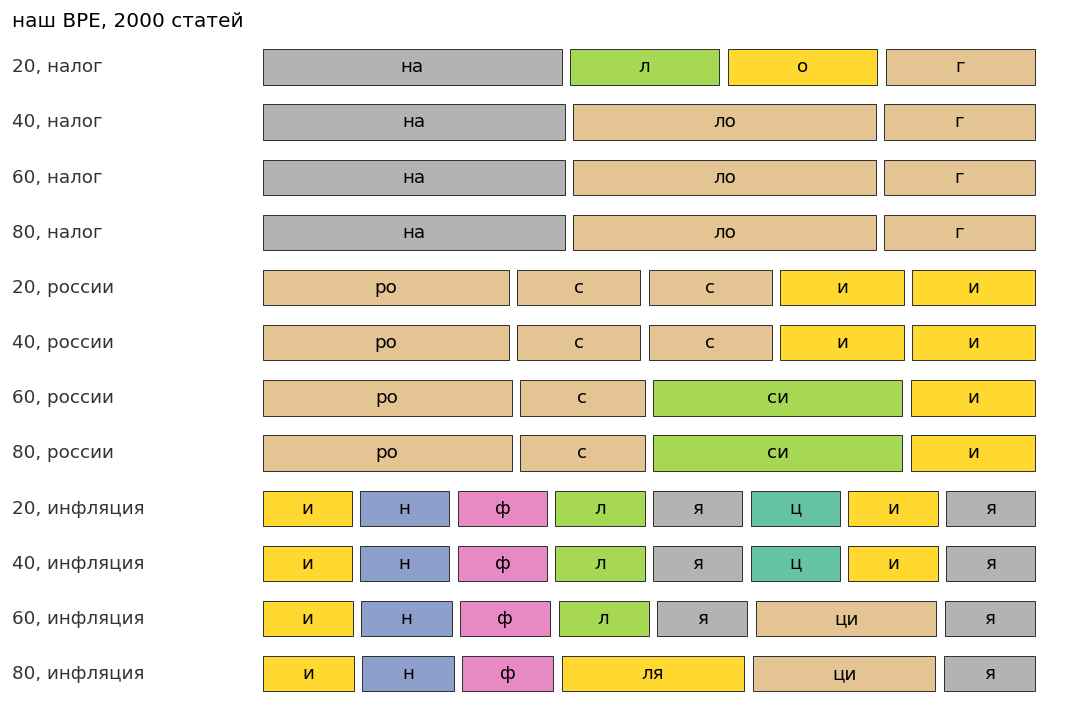

In [21]:
merges_g = []
saved_g = {0: []}


def show_step(step, merges):
    print(f"\nслияний {step:3d}   токенов {len(alphabet_g) + step}")
    for word in probe:
        print(f"  {word:16} {' '.join(encode_word(word, merges, alphabet_g))}")


show_step(0, [])
for step in tqdm(range(n_merges), desc="наш BPE"):
    best = most_frequent_pair(pair_counts(corpus_g))
    corpus_g = merge_corpus(corpus_g, best)
    merges_g.append(best)
    done = step + 1
    if done in stops:
        saved_g[done] = list(merges_g)
        show_step(done, merges_g)

show_tokens(
    [
        (f"{step}, {word}", encode_word(word, saved_g[step], alphabet_g))
        for word in ("налог", "россии", "инфляция")
        for step in stops[1:]
    ],
    title="наш BPE, 2000 статей",
)

## 4. Размер словаря

В библиотеке `tokenizers` крутят не число слияний, а `vocab_size`: буквы, служебные токены и все склейки вместе. `min_frequency=2` — пара, которая встретилась один раз, не склеивается.

Нижний регистр здесь уже не делаем. Для этой модели «России» и «россии» — разные слова.

### Задание

«России», «инфляция», «Центробанк». При каком `vocab_size` первое уже один токен, а второе ещё нет? Собирается ли «Центробанк» при 30000?

In [28]:
from tokenizers import Tokenizer
from tokenizers.models import BPE, WordPiece, Unigram
from tokenizers.pre_tokenizers import Whitespace
from tokenizers.trainers import BpeTrainer, WordPieceTrainer, UnigramTrainer


def train_hf_bpe(vocab_size):
    tokenizer = Tokenizer(BPE(unk_token="[UNK]"))
    tokenizer.pre_tokenizer = Whitespace()
    trainer = BpeTrainer(
        vocab_size=vocab_size,
        min_frequency=2,
        special_tokens=["[UNK]"],
        show_progress=True,
    )
    started = time.perf_counter()
    tokenizer.train_from_iterator(news, trainer=trainer)
    seconds = time.perf_counter() - started
    print(f"vocab_size {vocab_size:5d}   в словаре {tokenizer.get_vocab_size()}   {seconds:.1f} с")
    return tokenizer

In [54]:
tokenizer = train_hf_bpe(5_000)




vocab_size  5000   в словаре 5000   4.9 с


In [55]:
tokenizer.encode("Центробанк").tokens

['[UNK]', 'ен', 'тро', 'банк']

In [56]:
for word in ["Центробанк", "инфляция", "России"]:
    word = clean(word)
    print(word, tokenizer.encode(word).tokens)

центробанк ['цен', 'тро', 'банк']
инфляция ['инф', 'ля', 'ция']
россии ['россии']


## Решение

In [ ]:
# обучение
sizes = [500, 2000, 8000, 30000]
probe = ["России", "инфляция", "Центробанк", "нейросеть"]
trained = {}
for vocab_size in tqdm(sizes, desc="vocab_size"):
    trained[vocab_size] = train_hf_bpe(vocab_size)


россии
    500  ['россии']
   2000  ['россии']
   8000  ['россии']
  30000  ['россии']
инфляция
    500  ['ин', 'ф', 'ля', 'ция']
   2000  ['ин', 'ф', 'ля', 'ция']
   8000  ['инф', 'ляция']
  30000  ['инфляция']
центробанк
    500  ['цен', 'тро', 'ба', 'н', 'к']
   2000  ['цен', 'тро', 'бан', 'к']
   8000  ['центро', 'банк']
  30000  ['центробанк']
нейросеть
    500  ['ней', 'ро', 'с', 'ет', 'ь']
   2000  ['ней', 'ро', 'сет', 'ь']
   8000  ['ней', 'ро', 'сеть']
  30000  ['нейро', 'сеть']


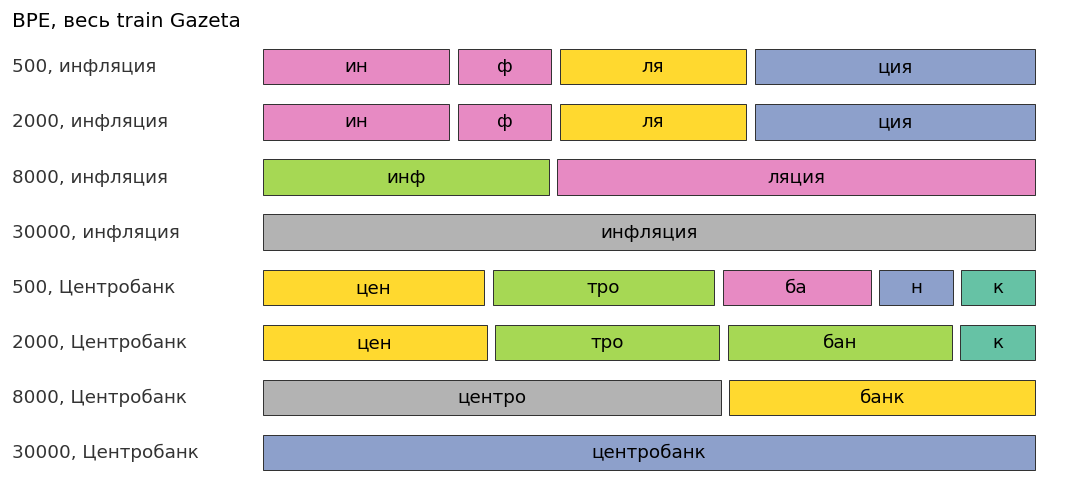

In [59]:
# инференс
print()
for word in probe:
    word = clean(word)
    print(word)
    for vocab_size in sizes:
        
        pieces = trained[vocab_size].encode(word).tokens
        print(f"  {vocab_size:5d}  {pieces}")

show_tokens(
    [
        (f"{vocab_size}, {word}", trained[vocab_size].encode(clean(word)).tokens)
        for word in ("инфляция", "Центробанк")
        for vocab_size in sizes
    ],
    title="BPE, весь train Gazeta",
)

In [63]:
from transformers import AutoTokenizer
ru_bert_tiny_tokenizer = AutoTokenizer.from_pretrained("cointegrated/rubert-tiny")

/Users/fedorkurushin/Documents/ChatGPT/seminars_mephi/transformers/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


In [ ]:
# ##ц ##е ##н ##т ##р ##о ##б ...

In [69]:
ru_bert_tiny_tokenizer("Центробанк").tokens()

['[CLS]', 'Центр', '##оба', '##нк', '[SEP]']

In [68]:
ru_bert_tiny_tokenizer("центробанк").tokens()

['[CLS]', 'центр', '##оба', '##нк', '[SEP]']

80 наших правил слово «инфляция» не собрали. На всём train при `vocab_size` 2000 «России» уже один токен: слово частое, пары внутри него склеились рано. «Инфляция» и «Центробанк» добираются до одного токена только к 30000. Размер словаря — главная ручка. Маленький словарь режет даже обычные слова.

## 5. Те же слова, три алгоритма

Один train, один `vocab_size` 8000. BPE уже обучен в ячейке выше. WordPiece и Unigram учим здесь. Unigram дольше, около полминуты.

In [ ]:
vocab_size = 8_000







россии
  BPE          ['россии']
  WordPiece    ['россии']
  Unigram      ['россии']
инфляция
  BPE          ['инф', 'ляция']
  WordPiece    ['инф', '##ляция']
  Unigram      ['инфляци', 'я']
центробанк
  BPE          ['центро', 'банк']
  WordPiece    ['центроб', '##анк']
  Unigram      ['центробанк']
нейросеть
  BPE          ['ней', 'ро', 'сеть']
  WordPiece    ['ней', '##рос', '##еть']
  Unigram      ['не', 'й', 'рос', 'е', 'ть']


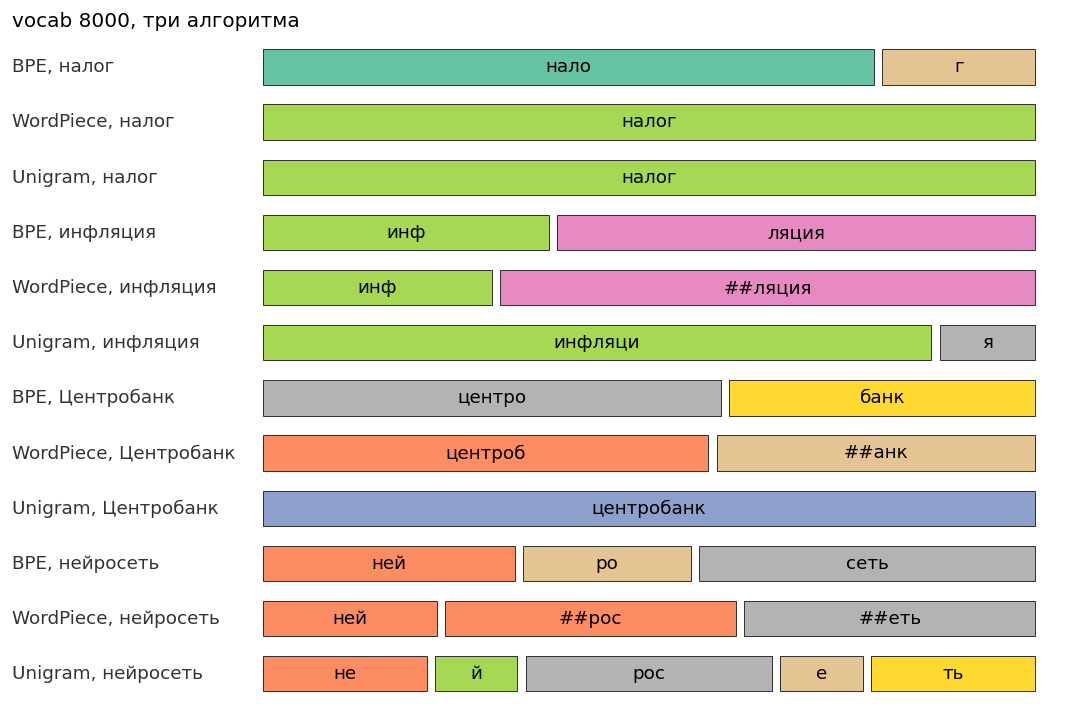

In [ ]:
def train_hf(model, Trainer, vocab_size, min_frequency=None):
    tokenizer = Tokenizer(model)
    tokenizer.pre_tokenizer = Whitespace()
    kwargs = dict(vocab_size=vocab_size, special_tokens=["[UNK]"], show_progress=True)
    if min_frequency is not None:
        kwargs["min_frequency"] = min_frequency
    trainer = Trainer(**kwargs)
    tokenizer.train_from_iterator(news, trainer=trainer)
    return tokenizer

# unigram_trainer = UnigramTrainer(vocab_size=8000, special_tokens=["[UNK]"], unk_token="[UNK]")

algos = {
    "BPE":  train_hf_bpe(vocab_size),
    "WordPiece": train_hf(WordPiece(unk_token="[UNK]"), WordPieceTrainer, vocab_size, min_frequency=2),
    "Unigram": train_hf(Unigram(), UnigramTrainer, vocab_size),  # unigram_trainer
}

print()
for word in probe:
    word = clean(word)
    print(word)
    for name, tokenizer in algos.items():
        print(f"  {name:12} {tokenizer.encode(word).tokens}")

show_tokens(
    [
        (f"{name}, {word}", tokenizer.encode(clean(word)).tokens)
        for word in ("налог", "инфляция", "Центробанк", "нейросеть")
        for name, tokenizer in algos.items()
    ],
    title="vocab 8000, три алгоритма",
)

Словарь одного размера, нарезка разная.

«налог» BPE ещё держит как «нало» + «г». WordPiece и Unigram уже отдают его целиком. «Центробанк» одним токеном собрал только Unigram. «нейросеть» Unigram почти рассыпал на буквы. `##` у WordPiece значит «этот кусок не с начала слова».

Критерий из раздела 1 здесь виден на одном и том же тексте: BPE догоняет частоту, WordPiece другие границы, Unigram другой набор токенов.

## 6. Если останется время. Токены BERT

Энкодер собирали на прошлом семинаре. Здесь только вход.

BERT режет текст алгоритмом WordPiece. Берём `bert-tiny` из `models/bert-tiny`, интернет не нужен. Словарь английский, 30522 токена. `##` на продолжении слова — то же соглашение, что в ячейке выше.

Русское слово разваливается на буквы: готовых русских слов в этом словаре нет. Модель для русского учат со своим словарём, например RuBERT. Токенизатор и матрицу эмбеддингов меняют вместе.

/Users/fedorkurushin/Documents/ChatGPT/seminars_mephi/transformers/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


unhappiness          ['un', '##ha', '##pp', '##iness']
tokenization         ['token', '##ization']
налог                ['н', '##а', '##л', '##о', '##г']
мама мыла раму       ['м', '##а', '##м', '##а', 'м', '##ы', '##л', '##а', 'р', '##а', '##м', '##у']


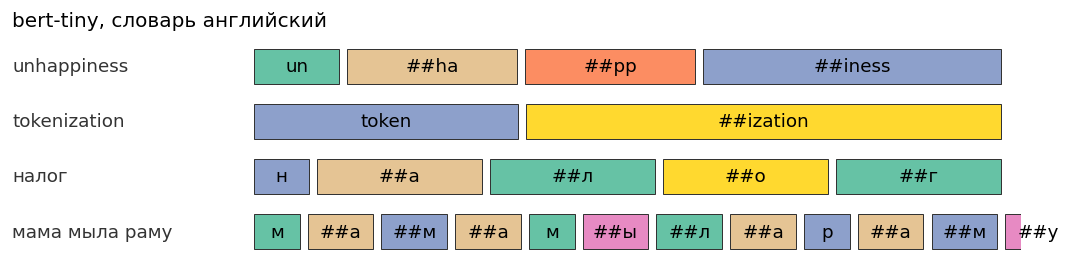


[CLS] 101  [SEP] 102  [PAD] 0  [MASK] 103  [UNK] 100


In [48]:
from transformers import BertTokenizer

tokenizer = BertTokenizer.from_pretrained("models/bert-tiny", local_files_only=True)

rows = []
for text in ["unhappiness", "tokenization", "налог", "мама мыла раму"]:
    pieces = tokenizer.tokenize(text)
    print(f"{text:20} {pieces}")
    rows.append((text, pieces))

show_tokens(rows, title="bert-tiny, словарь английский")
print()
print("[CLS]", tokenizer.cls_token_id, " [SEP]", tokenizer.sep_token_id,
      " [PAD]", tokenizer.pad_token_id, " [MASK]", tokenizer.mask_token_id,
      " [UNK]", tokenizer.unk_token_id)

Служебные токены сидят в том же словаре:

- `[CLS]` ставится первым. На классификации текста берут вектор этой позиции.
- `[SEP]` ставится между двумя текстами и в конце. Вопрос и абзац склеивают в одну последовательность, отдельную модель на пару текстов не делают.
- `[PAD]` добивает короткие строки в батче. На прошлом семинаре это был `<pad>`, маска внимания на нём нулевая.
- `[MASK]` стоит на месте спрятанного слова в предобучении.
- `[UNK]` — кусок, которого нет в словаре.

К эмбеддингу токена прибавляют эмбеддинг позиции, как на прошлом семинаре, и эмбеддинг сегмента. Сегмент 0 — первый текст, сегмент 1 — второй.

```
вход = эмбеддинг токена + эмбеддинг сегмента + эмбеддинг позиции
```

[CLS]     сегмент 0  маска 1
the       сегмент 0  маска 1
cat       сегмент 0  маска 1
sat       сегмент 0  маска 1
[SEP]     сегмент 0  маска 1
on        сегмент 1  маска 1
the       сегмент 1  маска 1
mat       сегмент 1  маска 1
[SEP]     сегмент 1  маска 1


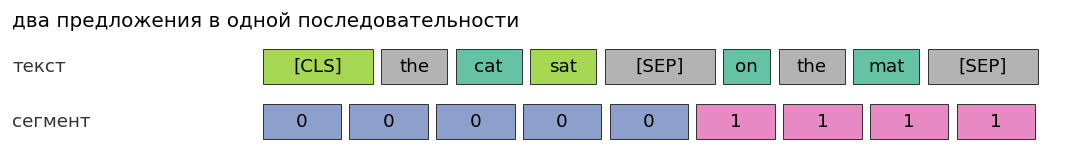

In [49]:
encoded = tokenizer("the cat sat", "on the mat")
tokens = tokenizer.convert_ids_to_tokens(encoded["input_ids"])
for tok, seg, keep in zip(tokens, encoded["token_type_ids"], encoded["attention_mask"]):
    print(f"{tok:8}  сегмент {seg}  маска {keep}")

show_tokens([
    ("текст", tokens),
    ("сегмент", [str(s) for s in encoded["token_type_ids"]]),
], title="два предложения в одной последовательности")

Энкодер видит все токены сразу. Учить «следующее слово», как в языковой модели, бессмысленно: слово и так лежит справа. Поэтому при предобучении часть позиций прячут и просят восстановить токен по остальным. Это masked language model.

Выбирают 15% позиций. Их и надо предсказать. На месте токена:

- в 80% случаев пишут `[MASK]`;
- в 10% подставляют случайный токен;
- в 10% оставляют исходный.

Позицию предсказывают во всех трёх случаях. Если бы дырка всегда была `[MASK]`, модель привыкла бы к символу, которого нет в обычном тексте.

Ниже три позиции выбраны руками, чтобы увидеть все три ветки. В обучении это случайные 15%, спецтокены `[CLS]` и `[SEP]` не маскируют.

В статье была вторая задача: угадать, идёт ли второе предложение следом за первым. Позже её убрали, качество не просело. Сегодня её не кодим.

было     стало    предсказать
[CLS]    [CLS]    —
the      the      —
cat      [MASK]   cat
sat      sat      —
on       dog      on
the      the      —
mat      mat      mat
[SEP]    [SEP]    —


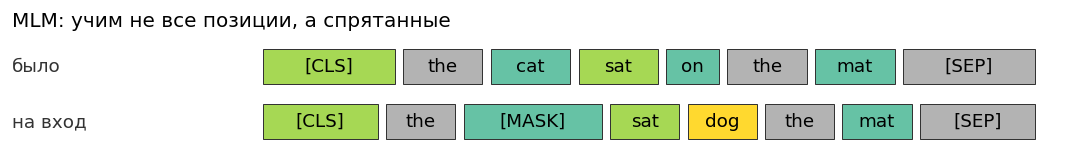

In [50]:
sentence = ["[CLS]", "the", "cat", "sat", "on", "the", "mat", "[SEP]"]
# позиция -> что с ней сделать. Так видно все три ветки сразу.
plan = {2: "mask", 4: "random", 6: "keep"}
random_token = "dog"

out = sentence.copy()
for i, kind in plan.items():
    if kind == "mask":
        out[i] = "[MASK]"
    elif kind == "random":
        out[i] = random_token

print(f"{'было':8} {'стало':8} предсказать")
for i, (src, dst) in enumerate(zip(sentence, out)):
    target = src if i in plan else "—"
    print(f"{src:8} {dst:8} {target}")

show_tokens([
    ("было", sentence),
    ("на вход", out),
], title="MLM: учим не все позиции, а спрятанные")

## 7. Контрольные вопросы

1. Почему первой склеивается пара «с» + «т», хотя это не морфема?
2. В 2000 статьях «инфляция» встретилась десятки раз, «россии» — тысячи. Почему при 80 слияниях ни то ни другое ещё не один токен?
3. На всём train при `vocab_size` 2000 «России» уже один токен, а «инфляция» ещё нет. Что именно от этого размера зависит?
4. WordPiece на тех же 8000 токенах режет «Центробанк» иначе, чем BPE. Какое у него правило вместо «самая частая пара»?
5. Зачем на продолжении слова стоит `##`?
6. Зачем в MLM иногда оставлять исходный токен, а не писать `[MASK]`?

## 8. Короткий конспект

- BPE клеит самую частую соседнюю пару. WordPiece клеит пару с наибольшим $\mathrm{freq}(AB) / (\mathrm{freq}(A)\,\mathrm{freq}(B))$ и на тексте берёт самый длинный кусок. Unigram выкидывает лишние токены из большого словаря.
- GPT-линейка сидит на BPE, BERT на WordPiece, многоязычные модели чаще на Unigram внутри SentencePiece.
- Частоты для нашего BPE посчитаны по 2000 статьям Gazeta. Первая пара — «с» + «т», потому что так вышло по счётчику.
- Новое слово режут списком правил: каждый раз клеят пару с наименьшим номером.
- `vocab_size` решает, дособралось ли слово. 80 правил на куске train и 30000 токенов на всём train — разный словарь.
- При одном и том же размере три алгоритма режут одни и те же слова по-разному.
- Токенизатор обученной модели не меняют: номера прибиты к эмбеддингам.
- BERT прячет около 15% токенов и восстанавливает их по левому и правому контексту. Не каждая дырка записана как `[MASK]`.